# EDA: Travel Planning and Booking Agent

**Goal:** understand the fixed dataset *before* building the agent. Every finding ends with
**"so the agent will …"** — these sentences become the design requirements for Phase 2.

The data is read-only. This notebook only reads from `data/` and `calendars/` (paths come from
`travel_agent.config`). Text inside the data (requests, disruption messages, calendar entries)
is treated as data, never as instructions.

**Contents**
1. Profile of every file
2. How the files fit together
3. Source consistency (flights: search vs booking, hotels: listing vs details)
4. Coverage: cities, dates, prices, seats
5. Activities, opening days and weather
6. Calendars
7. Trip requests: what is easy, hard or impossible
8. Disruptions
9. Tool failures (`fault_config.json`)
10. Summary: design requirements

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd
from icalendar import Calendar
from IPython.display import display

from travel_agent import config

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 90)


def load_json(path):
    with open(path) as f:
        return json.load(f)


def load_jsonl(path):
    with open(path) as f:
        return [json.loads(line) for line in f if line.strip()]


flights = pd.DataFrame(load_json(config.FLIGHTS_FILE))
booking_prices = load_json(config.FLIGHT_BOOKING_PRICES_FILE)  # dict: flight_id -> price
hotels_listing = pd.DataFrame(load_json(config.HOTELS_LISTING_FILE))
hotels_details = pd.DataFrame(load_json(config.HOTELS_DETAILS_FILE))
activities = pd.DataFrame(load_json(config.ACTIVITIES_FILE))
weather = pd.DataFrame(load_json(config.WEATHER_FILE))
personas = pd.DataFrame(load_json(config.PERSONAS_FILE))
fault_config = load_json(config.FAULT_CONFIG_FILE)
trip_requests = pd.DataFrame(load_jsonl(config.TRIP_REQUESTS_FILE))
disruptions = pd.DataFrame(load_jsonl(config.DISRUPTIONS_FILE))

# Calendars (.ics) -> one row per event
rows = []
for pid in personas.persona_id:
    cal = Calendar.from_ical(config.calendar_file(pid).read_bytes())
    for ev in cal.walk("VEVENT"):
        rows.append({
            "persona_id": pid,
            "start": ev.decoded("DTSTART"),
            "end": ev.decoded("DTEND"),
            "summary": str(ev.get("SUMMARY")),
        })
calendar_events = pd.DataFrame(rows)
calendar_events["start"] = pd.to_datetime(calendar_events["start"])
calendar_events["end"] = pd.to_datetime(calendar_events["end"])

# Chart style: one hue, recessive axes and grid
BLUE = "#2a78d6"
INK_2 = "#52514e"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK_2,
    "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.grid": True, "grid.color": "#e8e7e3", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "font.size": 10,
})

## 1. Profile of every file
Rows, columns, missing values and duplicates. Nested fields (dicts/lists) are serialised so
duplicates can be counted.

In [2]:
def profile(name, df, id_col=None):
    hashable = df.map(lambda v: json.dumps(v, sort_keys=True) if isinstance(v, (dict, list)) else v)
    return {
        "file": name,
        "rows": len(df),
        "columns": df.shape[1],
        "missing_values": int(df.isna().sum().sum()),
        "duplicate_rows": int(hashable.duplicated().sum()),
        "duplicate_ids": int(df[id_col].duplicated().sum()) if id_col else None,
    }


booking_df = pd.DataFrame(list(booking_prices.items()), columns=["flight_id", "booking_price"])
pd.DataFrame([
    profile("flights.json", flights, "flight_id"),
    profile("flight_booking_prices.json", booking_df, "flight_id"),
    profile("hotels_listing.json", hotels_listing, "hotel_id"),
    profile("hotels_details.json", hotels_details, "hotel_id"),
    profile("activities.json", activities, "activity_id"),
    profile("weather.json", weather),
    profile("personas.json", personas, "persona_id"),
    profile("trip_requests.jsonl", trip_requests, "request_id"),
    profile("disruptions.jsonl", disruptions, "event_id"),
    profile("calendars/*.ics", calendar_events),
])

,file,rows,columns,missing_values,duplicate_rows,duplicate_ids
0,flights.json,207,10,0,0,0.0
1,flight_booking_prices.json,207,2,0,0,0.0
2,hotels_listing.json,87,9,0,0,0.0
3,hotels_details.json,87,6,0,0,0.0
4,activities.json,100,8,0,0,0.0
5,weather.json,300,5,0,0,NaN
6,personas.json,3,6,0,0,0.0
7,trip_requests.jsonl,10,3,0,0,0.0
8,disruptions.jsonl,5,4,0,0,0.0
9,calendars/*.ics,10,4,0,0,NaN


In [3]:
for name, df in [("flights", flights), ("hotels_listing", hotels_listing), ("hotels_details", hotels_details),
                 ("activities", activities), ("weather", weather)]:
    print(f"--- {name}")
    display(df.head(3))

--- flights


,flight_id,airline,origin,destination,depart,arrive,price,currency,stops,seats_left
0,FL-0001,EuroHop,BER,LIS,2026-11-13T14:30,2026-11-13T17:54,58.0,EUR,0,33
1,FL-0002,Aerolux,BER,LIS,2026-11-13T06:40,2026-11-13T09:16,99.0,EUR,0,7
2,FL-0003,EuroHop,BER,LIS,2026-11-13T19:20,2026-11-13T23:02,72.0,EUR,1,17


--- hotels_listing


,hotel_id,city,name,stars,rating,price_per_night,amenities,accessibility,cancellation_policy
0,HT-001,LIS,Hotel Old Town Lisbon 1,5,4.4,174.0,"[wifi, breakfast, spa, pool]","{'step_free': False, 'elevator': False}",free_cancellation
1,HT-002,LIS,Hotel Grand Lisbon 2,3,4.2,120.0,"[wifi, breakfast, lift, pool, gym]","{'step_free': False, 'elevator': True}",free_until_48h
2,HT-003,LIS,Hotel Old Town Lisbon 3,4,4.3,119.0,"[wifi, breakfast, bar, spa]","{'step_free': False, 'elevator': False}",non_refundable


--- hotels_details


,hotel_id,price_per_night,step_free_entrance,elevator,breakfast_included,cancellation_policy
0,HT-001,174.0,False,False,True,free_cancellation
1,HT-002,120.0,False,True,True,free_until_48h
2,HT-003,119.0,False,False,True,free_until_48h


--- activities


,activity_id,city,name,type,duration_h,price,outdoor,opening_hours
0,AC-001,LIS,Lisbon food tour,food_tour,2,12.0,False,"{'Mon': '10:00-22:00', 'Tue': '10:00-22:00', 'Wed': '10:00-22:00', 'Thu': '10:00-22:00..."
1,AC-002,LIS,Lisbon spa,spa,4,49.0,False,"{'Mon': '09:00-18:00', 'Tue': 'closed', 'Wed': '09:00-18:00', 'Thu': '09:00-18:00', 'F..."
2,AC-003,LIS,Lisbon night walk,night_walk,1,35.0,True,"{'Mon': '10:00-22:00', 'Tue': 'closed', 'Wed': '10:00-22:00', 'Thu': '10:00-22:00', 'F..."


--- weather


,city,date,temp_c,precipitation_prob,condition
0,LIS,2026-11-01,13.1,0.49,cloudy
1,LIS,2026-11-02,14.2,0.32,sunny
2,LIS,2026-11-03,16.9,0.53,cloudy


**Finding 1 – Technically clean, semantically tricky.** No file has missing values, duplicate rows
or duplicate IDs. Every flight in `flights.json` has a booking price, every hotel in
`hotels_listing.json` has a details record. All prices are in EUR, all dates are November 2026.
The problems in this dataset are not gaps — they are **contradictions between sources** (section 3)
and **ambiguous values** (e.g. 27 activities with price `0.0`, section 5).

→ **So the agent will** not need data cleaning or imputation, but it must cross-check sources
before it trusts a value.

## 2. How the files fit together

```
personas (T1–T3) ──home_airport──► flights.origin / flights.destination
  │  └── calendars/T1.ics … T3.ics (same persona_id)
  └── persona_id ◄── trip_requests (R01–R10) ◄── request_id ── disruptions (D1–D5)

flights ──flight_id──► flight_booking_prices          (search price vs booking price)
hotels_listing ──hotel_id──► hotels_details           (listing vs details)

city code (LIS, BCN, AMS, …) joins flights.destination ↔ hotels.city ↔ activities.city ↔ weather.city
```

In [4]:
hubs = set(personas.home_airport)
print("Home airports (personas):", sorted(hubs))
print("Flight IDs without booking price:", set(flights.flight_id) - set(booking_prices))
print("Booking prices without flight:  ", set(booking_prices) - set(flights.flight_id))
print("Hotels without details:         ", set(hotels_listing.hotel_id) - set(hotels_details.hotel_id))
print("Requests with unknown persona:  ", set(trip_requests.persona_id) - set(personas.persona_id))
print("Disruptions with unknown request:", set(disruptions.request_id) - set(trip_requests.request_id))
print("Flights between two home airports:",
      len(flights[flights.origin.isin(hubs) & flights.destination.isin(hubs)]))

dest_cities = sorted(set(flights.destination) - hubs)
coverage = pd.DataFrame({
    "flights_from_hubs": flights[flights.origin.isin(hubs)].destination.value_counts(),
    "flights_to_hubs": flights[flights.destination.isin(hubs)].origin.value_counts(),
    "hotels": hotels_listing.city.value_counts(),
    "activities": activities.city.value_counts(),
    "weather_days": weather.city.value_counts(),
}).loc[dest_cities].fillna(0).astype(int)
coverage

Home airports (personas): ['BER', 'FRA', 'MUC']
Flight IDs without booking price: set()
Booking prices without flight:   set()
Hotels without details:          set()
Requests with unknown persona:   set()
Disruptions with unknown request: set()
Flights between two home airports: 0


,flights_from_hubs,flights_to_hubs,hotels,activities,weather_days
AMS,14,13,11,10,30
ATH,9,9,8,10,30
BCN,12,11,10,10,30
FCO,9,9,8,10,30
LIS,12,11,9,10,30
PMO,9,9,8,10,30
PRG,11,11,9,10,30
SPU,9,9,8,10,30
VIE,11,11,8,10,30
VLC,9,9,8,10,30


**Finding 2 – One clean star network.** All IDs join without orphans. Every trip starts at one of
three home airports (BER, MUC, FRA) and goes to one of 10 destinations (AMS, ATH, BCN, FCO, LIS,
PMO, PRG, SPU, VIE, VLC). Each destination has hotels (8–11), exactly 10 activities and 30 weather
days. There are no flights between the home airports and no hotels/activities/weather for them.
City codes are airport codes (FCO = Rome, SPU = Split, PMO = Palermo, VLC = Valencia).

→ **So the agent will** build one "destination" key from the airport code, map city names in
user text (e.g. "Rome") to these codes, and tell the user clearly when a city or origin is
outside this network instead of inventing options.

## 3. Source consistency
### 3a. Flights: search price vs booking price

In [5]:
flights["booking_price"] = flights.flight_id.map(booking_prices)
flights["price_diff"] = flights.booking_price - flights.price
flights["day"] = flights.depart.str[:10]

changed = flights[flights.price_diff != 0]
print(f"{len(changed)} of {len(flights)} flights ({len(changed)/len(flights):.0%}) have a different booking price.")
print(f"Booking price lower than search price: {(flights.price_diff < 0).sum()} flights")
print(f"Difference: +{changed.price_diff.min():.0f} to +{changed.price_diff.max():.0f} EUR "
      f"(up to +{(changed.price_diff / changed.price).max():.0%})")
changed.sort_values("price_diff", ascending=False)[
    ["flight_id", "origin", "destination", "depart", "price", "booking_price", "price_diff"]
]

24 of 207 flights (12%) have a different booking price.
Booking price lower than search price: 0 flights
Difference: +6 to +24 EUR (up to +24%)


,flight_id,origin,destination,depart,price,booking_price,price_diff
65,FL-0066,BER,AMS,2026-11-21T08:45,108.0,132.0,24.0
37,FL-0038,BCN,BER,2026-11-25T07:15,91.0,112.0,21.0
93,FL-0094,MUC,BCN,2026-11-18T13:30,83.0,103.0,20.0
106,FL-0107,MUC,PRG,2026-11-17T11:30,72.0,88.0,16.0
201,FL-0202,FRA,PMO,2026-11-17T15:15,99.0,114.0,15.0
170,FL-0171,PRG,FRA,2026-11-13T16:15,95.0,110.0,15.0
76,FL-0077,BER,SPU,2026-11-28T18:45,87.0,102.0,15.0
166,FL-0167,FRA,PRG,2026-11-19T15:00,60.0,74.0,14.0
174,FL-0175,VIE,FRA,2026-11-10T08:30,73.0,86.0,13.0
140,FL-0141,SPU,MUC,2026-11-24T11:45,61.0,74.0,13.0


**Finding 3a – The search price is optimistic.** 24 of 207 flights (12 %) cost more at booking
than in search, by +6 to +24 EUR; never less. The biggest jump is **FL-0066** (BER→AMS, 108 → 132).
This hits real requests: **FL-0003** (BER→LIS, 13 Nov 19:20) is the only R01 outbound flight after
T1's workshop (section 6) and goes from 72 to 82 EUR; the R01 return **FL-0005** goes from 78 to 85.

→ **So the agent will** treat the search price as an estimate, fetch the booking price for every
flight in the final plan, run the budget check on booking prices, and show the user any price
change before asking for confirmation.

### 3b. Hotels: listing vs details

In [6]:
hl = hotels_listing.copy()
hl["step_free"] = hl.accessibility.map(lambda a: a["step_free"])
hl["elevator"] = hl.accessibility.map(lambda a: a["elevator"])
hl["breakfast"] = hl.amenities.map(lambda a: "breakfast" in a)
hotels = hl.drop(columns=["accessibility"]).merge(
    hotels_details.rename(columns={"step_free_entrance": "step_free", "breakfast_included": "breakfast"}),
    on="hotel_id", suffixes=("_listing", "_details"),
)

conflicts = []
for field in ["price_per_night", "step_free", "elevator", "breakfast", "cancellation_policy"]:
    bad = hotels[hotels[f"{field}_listing"] != hotels[f"{field}_details"]]
    for _, r in bad.iterrows():
        conflicts.append({"hotel_id": r.hotel_id, "city": r.city, "name": r["name"], "field": field,
                          "listing": r[f"{field}_listing"], "details": r[f"{field}_details"]})
conflicts = pd.DataFrame(conflicts)
print(conflicts.field.value_counts().reindex(
    ["price_per_night", "step_free", "elevator", "breakfast", "cancellation_policy"], fill_value=0))
conflicts

field
price_per_night        4
step_free              4
elevator               0
breakfast              0
cancellation_policy    2
Name: count, dtype: int64


,hotel_id,city,name,field,listing,details
0,HT-005,LIS,Hotel Boutique Lisbon 5,price_per_night,117.0,134.0
1,HT-034,VIE,Hotel Riverside Vienna 2,price_per_night,96.0,118.0
2,HT-044,ATH,Hotel Riverside Athens 4,price_per_night,136.0,175.0
3,HT-080,PMO,Hotel Garden Palermo 8,price_per_night,78.0,97.0
4,HT-010,BCN,Hotel Grand Barcelona 2,step_free,False,True
5,HT-038,VIE,Hotel Riverside Vienna 6,step_free,False,True
6,HT-041,ATH,Hotel Old Town Athens 1,step_free,False,True
7,HT-086,AMS,Hotel Pijp Quartier,step_free,True,False
8,HT-003,LIS,Hotel Old Town Lisbon 3,cancellation_policy,non_refundable,free_until_48h
9,HT-014,BCN,Hotel Harbour Barcelona 6,cancellation_policy,non_refundable,free_until_48h


**Finding 3b – Listing and details disagree on exactly the fields that are hard constraints.**
10 conflicts in 87 hotels:
- **Price (4):** details always higher — HT-005 (+17), HT-034 (+22), HT-044 (+39), HT-080 (+19).
- **Step-free entrance (4):** **HT-086 "Hotel Pijp Quartier" (AMS)** is step-free in the listing but
  *not* in the details. This is the trap for R03 (family with a wheelchair user in Amsterdam).
  HT-010, HT-038, HT-041 are the other way round.
- **Cancellation (2):** HT-003 (LIS) and HT-014 (BCN) are `non_refundable` in the listing but
  `free_until_48h` in the details.
- Elevator and breakfast always agree.

If the agent trusted the listing (the first source it sees), it would book HT-086 for the Weber
family.

→ **So the agent will** always fetch hotel details before proposing a hotel; for a hard
constraint (accessibility, cancellation) it counts a hotel as compliant only if **both** sources
agree, and it uses the **higher** of the two prices. A conflict on a hard constraint is shown to
the user, not silently resolved.

## 4. Coverage: cities, dates, prices, seats

In [7]:
routes = flights[flights.origin.isin(hubs)]
days_with_flight = routes.groupby(["origin", "destination"]).day.nunique().unstack(fill_value=0)
print("Days in November with at least one outbound flight (out of 30):")
display(days_with_flight)
print("Flights per route and day:", routes.groupby(["origin", "destination", "day"]).size().value_counts().to_dict())
print("Date range:", flights.day.min(), "to", flights.day.max())
print("Flight price (search):", flights.price.describe()[["min", "50%", "max"]].to_dict())
print("Nonstop vs 1 stop:", flights.stops.value_counts().to_dict())
print("Flights with fewer than 4 seats left:", (flights.seats_left < 4).sum(),
      "→", flights[flights.seats_left < 4].flight_id.tolist())

Days in November with at least one outbound flight (out of 30):


destination,AMS,ATH,BCN,FCO,LIS,PMO,PRG,SPU,VIE,VLC
origin,,,,,,,,,,
BER,3,3,3,3,4,3,2,3,4,3
FRA,4,3,3,3,3,3,2,3,3,3
MUC,4,3,4,3,3,3,4,3,3,3


Flights per route and day: {1: 86, 2: 5, 3: 3}
Date range: 2026-11-01 to 2026-11-30
Flight price (search): {'min': 28.0, '50%': 65.0, 'max': 124.0}
Nonstop vs 1 stop: {0: 148, 1: 59}
Flights with fewer than 4 seats left: 9 → ['FL-0013', 'FL-0047', 'FL-0073', 'FL-0087', 'FL-0094', 'FL-0120', 'FL-0137', 'FL-0140', 'FL-0197']


In [8]:
hotels["price_safe"] = hotels[["price_per_night_listing", "price_per_night_details"]].max(axis=1)
hotels["accessible_both"] = (hotels.step_free_listing & hotels.step_free_details
                             & hotels.elevator_listing & hotels.elevator_details)
hotels["free_cancel_both"] = ((hotels.cancellation_policy_listing == "free_cancellation")
                              & (hotels.cancellation_policy_details == "free_cancellation"))
hotel_cov = hotels.groupby("city").agg(
    hotels=("hotel_id", "size"),
    cheapest=("price_safe", "min"),
    median=("price_safe", "median"),
    most_expensive=("price_safe", "max"),
    accessible_both_sources=("accessible_both", "sum"),
    free_cancellation_both=("free_cancel_both", "sum"),
)
hotel_cov

,hotels,cheapest,median,most_expensive,accessible_both_sources,free_cancellation_both
city,,,,,,
AMS,11,76.0,114.0,154.0,4,6
ATH,8,81.0,102.0,175.0,2,5
BCN,10,58.0,110.0,143.0,4,2
FCO,8,98.0,123.0,168.0,0,6
LIS,9,68.0,119.0,174.0,0,3
PMO,8,97.0,114.5,147.0,0,2
PRG,9,105.0,127.0,148.0,2,6
SPU,8,74.0,121.5,153.0,1,1
VIE,8,77.0,106.0,137.0,1,2


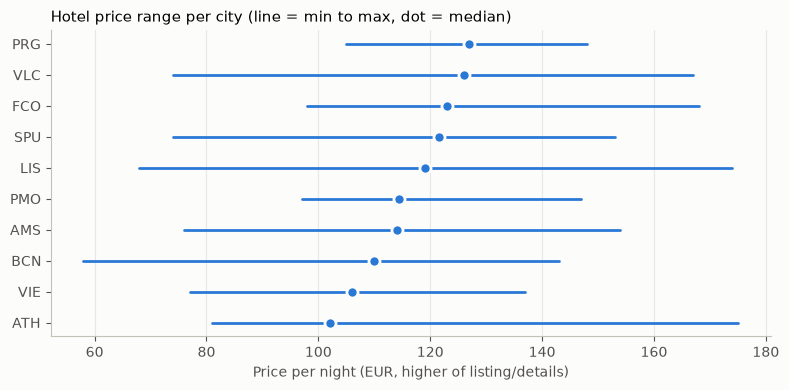

In [9]:
order = hotel_cov.sort_values("median").index
fig, ax = plt.subplots(figsize=(8, 4))
for i, city in enumerate(order):
    r = hotel_cov.loc[city]
    ax.plot([r.cheapest, r.most_expensive], [i, i], color=BLUE, linewidth=2, solid_capstyle="round")
    ax.plot(r["median"], i, "o", color=BLUE, markersize=8, markeredgecolor="#fcfcfb", markeredgewidth=2)
ax.set_yticks(range(len(order)), order)
ax.set_xlabel("Price per night (EUR, higher of listing/details)")
ax.set_title("Hotel price range per city (line = min to max, dot = median)", loc="left", fontsize=11)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Finding 4 – Coverage is narrow and sparse.** Only November 2026. A route has flights on just
2–4 days of the month, usually only 1 per day, so a fixed date often has no alternative at all.
Hotels cost 58–175 EUR per night; Prague is the most expensive city (cheapest 105), Barcelona has
the cheapest single hotel (HT-083, 58). **Accessible hotels are rare:** only hotels where *both*
sources say step-free *and* elevator count — Rome, Lisbon and Palermo have none, Amsterdam and Barcelona have 4.
Free cancellation (both sources) exists in every city. 9 flights have fewer than 4 seats left,
e.g. **FL-0013** (FRA→AMS, 6 Nov) has 2 seats — not enough for the Weber family.

Easy: short trips in November from a home airport with a flexible budget. Hard: fixed dates
(few alternatives), families (seats, accessibility), tight budgets. Impossible: anything
outside November, other origins/destinations, or below the cheapest flight + hotel sum.

→ **So the agent will** check `seats_left ≥ party size`, filter accessibility on both sources,
suggest nearby dates when a date has no flight, and say "not in our data" for anything outside
the network instead of guessing.

*Assumption (not stated in the data):* flight prices are per person, hotel prices are per room per
night, and one room is enough for the party. The agent must make this assumption visible in the plan.

## 5. Activities, opening days and weather

In [10]:
activities["closed_days"] = activities.opening_hours.map(lambda h: [d for d, v in h.items() if v == "closed"])
print("Opening-hour values:", sorted({v for h in activities.opening_hours for v in h.values()}))
print("Activity types per city:", activities.groupby("city").type.nunique().unique(), "(each city has every type once)")
print("Outdoor vs indoor:", activities.outdoor.value_counts().to_dict())
print("Activities closed on one weekday:", (activities.closed_days.str.len() > 0).sum(),
      activities.closed_days.explode().value_counts().to_dict())
print("Activities with price 0.0:", (activities.price == 0).sum())
print("Fields:", activities.columns.tolist()[:8], "→ no accessibility / walking information")
activities[activities.closed_days.str.len() > 0][["activity_id", "city", "name", "outdoor", "closed_days"]]

Opening-hour values: ['09:00-18:00', '10:00-22:00', 'closed']
Activity types per city: [10] (each city has every type once)
Outdoor vs indoor: {False: 50, True: 50}
Activities closed on one weekday: 26 {'Mon': 15, 'Tue': 11}
Activities with price 0.0: 27
Fields: ['activity_id', 'city', 'name', 'type', 'duration_h', 'price', 'outdoor', 'opening_hours'] → no accessibility / walking information


,activity_id,city,name,outdoor,closed_days
1,AC-002,LIS,Lisbon spa,False,[Tue]
2,AC-003,LIS,Lisbon night walk,True,[Tue]
3,AC-004,LIS,Lisbon museum,False,[Tue]
4,AC-005,LIS,Lisbon cooking workshop,False,[Mon]
10,AC-011,BCN,Barcelona food tour,False,[Mon]
12,AC-013,BCN,Barcelona museum,False,[Tue]
16,AC-017,BCN,Barcelona spa,False,[Tue]
18,AC-019,BCN,Barcelona guided tour,False,[Mon]
21,AC-022,FCO,Rome guided tour,False,[Mon]
26,AC-027,FCO,Rome food tour,False,[Tue]


In [11]:
print("Weather:", weather.date.min(), "to", weather.date.max(), "| conditions:", weather.condition.value_counts().to_dict())
wx = weather.groupby("city").agg(
    avg_temp_c=("temp_c", "mean"),
    max_temp_c=("temp_c", "max"),
    avg_rain_prob=("precipitation_prob", "mean"),
    sunny_days=("condition", lambda s: (s == "sunny").sum()),
    rain_days=("condition", lambda s: (s == "rain").sum()),
).round(1).sort_values("avg_temp_c", ascending=False)
wx

Weather: 2026-11-01 to 2026-11-30 | conditions: {'cloudy': 156, 'sunny': 116, 'rain': 28}


,avg_temp_c,max_temp_c,avg_rain_prob,sunny_days,rain_days
city,,,,,
PMO,17.3,20.6,0.4,12,0
VLC,16.3,18.8,0.3,18,0
ATH,15.4,18.3,0.4,11,0
LIS,14.7,18.0,0.4,11,2
BCN,14.2,17.4,0.3,14,0
SPU,12.9,16.1,0.4,11,2
FCO,12.3,15.4,0.4,9,7
AMS,7.1,10.3,0.6,0,17
VIE,5.4,8.6,0.3,17,0


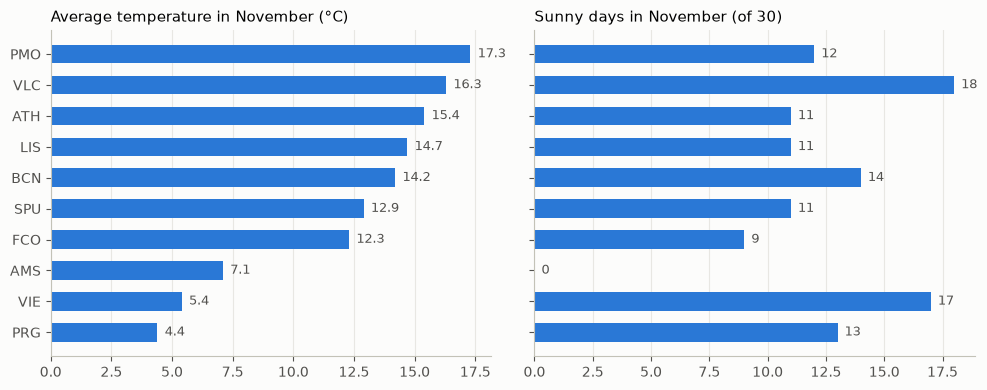

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
order = wx.index[::-1]
for ax, col, title in [(axes[0], "avg_temp_c", "Average temperature in November (°C)"),
                       (axes[1], "sunny_days", "Sunny days in November (of 30)")]:
    ax.barh(order, wx.loc[order, col], color=BLUE, height=0.6)
    ax.set_title(title, loc="left", fontsize=11)
    ax.grid(axis="y", visible=False)
    for y, v in enumerate(wx.loc[order, col]):
        ax.text(v + 0.3, y, f"{v:g}", va="center", color=INK_2, fontsize=9)
plt.tight_layout()
plt.show()

**Finding 5 – Plans must be checked day by day.** Each city has one activity of each of the 10
types, half of them outdoor. 26 activities are closed on one weekday (Monday or Tuesday), e.g.
AC-011 Barcelona food tour and AC-019 Barcelona guided tour are closed on Mondays — relevant for
R02, which ends on Monday 23 Nov. 27 activities have price `0.0`: this may mean "free" or "price
unknown". Activities have **no accessibility or walking data**, so R07 ("without a lot of walking")
cannot be verified from the data.

Weather only knows `sunny`, `cloudy` and `rain` — there is no storm anywhere. Warmest:
Palermo (17.3 °C), Valencia, Athens, Lisbon. **Amsterdam has 0 sunny days in November** and the
highest rain probability, so R09 ("we want sunshine … outdoors every day") cannot be fulfilled.

→ **So the agent will** check opening days for every scheduled date, prefer indoor activities on
days with high rain probability, label `0.0` prices as "free (unverified)", say explicitly that it
cannot verify walking effort or accessibility of activities, and use the weather data to define
"warm" (e.g. PMO, VLC, ATH, LIS).

## 6. Calendars

In [13]:
calendar_events.sort_values(["persona_id", "start"])

,persona_id,start,end,summary
0,T1,2026-11-05 16:00:00,2026-11-05 17:00:00,Dentist appointment
1,T1,2026-11-13 12:00:00,2026-11-13 17:00:00,Team workshop (Berlin office)
2,T1,2026-11-20 00:00:00,2026-11-20 23:59:00,Project delivery deadline
3,T1,2026-11-27 18:00:00,2026-11-27 19:30:00,Yoga class
4,T2,2026-11-14 19:00:00,2026-11-14 23:00:00,Friend's birthday dinner (Munich)
5,T2,2026-11-18 09:00:00,2026-11-18 10:00:00,Dentist
6,T2,2026-11-25 00:00:00,2026-11-25 23:59:00,Parents visiting
7,T3,2026-11-04 18:00:00,2026-11-04 19:30:00,Parent-teacher meeting
8,T3,2026-11-06 08:00:00,2026-11-06 15:00:00,School until 15:00 (children)
9,T3,2026-11-12 10:00:00,2026-11-12 11:00:00,Wheelchair service appointment


**Finding 6 – Three requests collide with the traveller's calendar.**
- **R01 (T1):** "Team workshop (Berlin office)" on Fri 13 Nov 12:00–17:00 — the outbound day.
  Only flights after 17:00 are possible.
- **R03 (T3):** "School until 15:00 (children)" on Fri 6 Nov — the outbound day.
- **R08 (T2):** "Friend's birthday dinner (Munich)" on Sat 14 Nov 19:00–23:00 — the outbound day,
  in the home city. No flight leaves MUC after 23:00.
- **R06 (T1):** "Project delivery deadline" is all day on 20 Nov, so "after my project ends on the
  20th" means departure on 21 Nov at the earliest.

The calendar events have no location field; the place only appears in the free text of the
summary.

→ **So the agent will** read the calendar before proposing times, only offer flights that leave
after the last event on the departure day (plus a buffer it states), and when a conflict cannot
be avoided, name the event and ask instead of choosing for the user.

## 7. Trip requests: easy, hard or impossible
For the six requests with a clear city and dates, compute the cheapest plan that respects all hard
constraints: booking prices, the higher hotel price, both-source hotel checks, `seats_left`, and
the calendar on the departure day. Activities are not included.

In [14]:
trip_requests.merge(personas[["persona_id", "name", "home_airport", "usual_party", "accessibility_needs"]], on="persona_id")

,request_id,persona_id,text,name,home_airport,usual_party,accessibility_needs
0,R01,T1,I'd like to go to Lisbon from Friday 13 November to Monday 16 November. Just me. Budge...,Mia Berger,BER,1,none
1,R02,T2,"We want to go to Barcelona from Friday 20 November to Monday 23 November. Two of us, 1...",Jonas and Elif,MUC,2,none
2,R03,T3,"Family trip to Amsterdam from Friday 6 November to Sunday 8 November, all four of us, ...",The Weber family,FRA,4,step-free hotel with lift
3,R04,T1,"A long weekend somewhere warm, under 800 euros.",Mia Berger,BER,1,none
4,R05,T2,"Surprise us with a cultural city break, nothing too expensive.",Jonas and Elif,MUC,2,none
5,R06,T1,I need to get away for a few days after my project ends on the 20th.,Mia Berger,BER,1,none
6,R07,T3,Somewhere the whole family can enjoy without a lot of walking.,The Weber family,FRA,4,step-free hotel with lift
7,R08,T2,"Prague from 14 to 16 November, two people, 300 euros total, and we want a 4-star hotel...",Jonas and Elif,MUC,2,none
8,R09,T2,Amsterdam from 27 to 29 November for the two of us. We want sunshine and to be outdoor...,Jonas and Elif,MUC,2,none
9,R10,T1,"Vienna from 2 to 4 November, just me, 120 euros total including flights and hotel.",Mia Berger,BER,1,none


In [15]:
home = dict(zip(personas.persona_id, personas.home_airport))


def busy_until(persona_id, day):
    """End of the last calendar event on that day (None if the day is free)."""
    ev = calendar_events[(calendar_events.persona_id == persona_id) & (calendar_events.start.dt.date == pd.Timestamp(day).date())]
    return ev.end.max() if len(ev) else None


def cheapest_trip(persona_id, dest, out_day, ret_day, party, hotel_ok=lambda h: True, buffer_h=0):
    origin = home[persona_id]
    nights = (pd.Timestamp(ret_day) - pd.Timestamp(out_day)).days
    out = flights[(flights.origin == origin) & (flights.destination == dest) & (flights.day == out_day)
                  & (flights.seats_left >= party)]
    blocked = busy_until(persona_id, out_day)
    if blocked is not None:
        out = out[pd.to_datetime(out.depart) >= blocked + pd.Timedelta(hours=buffer_h)]
    back = flights[(flights.origin == dest) & (flights.destination == origin) & (flights.day == ret_day)
                   & (flights.seats_left >= party)]
    cand = hotels[(hotels.city == dest) & hotels.apply(hotel_ok, axis=1)]
    if out.empty or back.empty or cand.empty:
        missing = [n for n, d in [("outbound flight", out), ("return flight", back), ("hotel", cand)] if d.empty]
        return {"feasible_inputs": False, "missing": ", ".join(missing)}
    f_out = out.loc[out.booking_price.idxmin()]
    f_back = back.loc[back.booking_price.idxmin()]
    h = cand.loc[cand.price_safe.idxmin()]
    total = party * (f_out.booking_price + f_back.booking_price) + nights * h.price_safe
    return {"feasible_inputs": True, "outbound": f"{f_out.flight_id} {f_out.depart[11:]}",
            "return": f"{f_back.flight_id} {f_back.depart[11:]}", "hotel": h.hotel_id,
            "flights_eur": party * (f_out.booking_price + f_back.booking_price),
            "hotel_eur": nights * h.price_safe, "cheapest_total": total}


free_cancel = lambda h: h.free_cancel_both
accessible = lambda h: h.accessible_both
four_star_breakfast = lambda h: h.stars >= 4 and h.breakfast_listing and h.breakfast_details

cases = [
    ("R01", "T1", "LIS", "2026-11-13", "2026-11-16", 1, free_cancel, 0, 450),
    ("R02", "T2", "BCN", "2026-11-20", "2026-11-23", 2, lambda h: True, 0, 1100),
    ("R03", "T3", "AMS", "2026-11-06", "2026-11-08", 4, accessible, 0, 1500),
    ("R03 (2h buffer after school)", "T3", "AMS", "2026-11-06", "2026-11-08", 4, accessible, 2, 1500),
    ("R08", "T2", "PRG", "2026-11-14", "2026-11-16", 2, four_star_breakfast, 0, 300),
    ("R08 (ignoring calendar)", "T2", "PRG", "2026-11-14", "2026-11-16", 2, four_star_breakfast, -24, 300),
    ("R09", "T2", "AMS", "2026-11-27", "2026-11-29", 2, lambda h: True, 0, None),
    ("R10", "T1", "VIE", "2026-11-02", "2026-11-04", 1, lambda h: True, 0, 120),
]
results = []
for label, pid, dest, d_out, d_ret, party, ok, buf, budget in cases:
    r = cheapest_trip(pid, dest, d_out, d_ret, party, ok, buf)
    r = {"case": label, "budget": budget, **r}
    if r["feasible_inputs"] and budget is not None:
        r["within_budget"] = r["cheapest_total"] <= budget
    results.append(r)
pd.DataFrame(results).set_index("case")

,budget,feasible_inputs,outbound,return,hotel,flights_eur,hotel_eur,cheapest_total,within_budget,missing
case,,,,,,,,,,
R01,450.0,True,FL-0003 19:20,FL-0004 10:30,HT-081,147.0,204.0,351.0,True,NaN
R02,1100.0,True,FL-0008 18:05,FL-0010 17:55,HT-083,286.0,174.0,460.0,True,NaN
R03,1500.0,True,FL-0012 16:10,FL-0015 20:10,HT-052,428.0,206.0,634.0,True,NaN
R03 (2h buffer after school),1500.0,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,outbound flight
R08,300.0,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,outbound flight
R08 (ignoring calendar),300.0,True,FL-0021 17:10,FL-0023 18:20,HT-087,320.0,210.0,530.0,False,NaN
R09,NaN,True,FL-0017 15:30,FL-0019 19:00,HT-055,284.0,152.0,436.0,NaN,NaN
R10,120.0,True,FL-0025 16:00,FL-0027 19:10,HT-040,135.0,154.0,289.0,False,NaN


*(The "ignoring calendar" row uses a buffer of −24 h, i.e. it lets every flight of that day through.)*

**Finding 7 – The ten requests test different skills.**

| Request | Type | What the data says |
|---|---|---|
| R01 Lisbon, 450 € | clear | Feasible: FL-0003 (after workshop) + FL-0004 + HT-081 = 351 €. Trap: FL-0003 is 72 € in search, 82 € at booking. |
| R02 Barcelona, 1100 € | clear | Easy: cheapest flights + hotel = 460 € for two, plenty left for activities. Monday 23 Nov: some activities closed. |
| R03 Amsterdam, family, 1500 € | clear, hard | Feasible only with FL-0012 (16:10, 70 min after school ends) — FL-0013 has 2 seats, FL-0011 is during school. Hotel must be accessible in both sources (HT-052/085/084/049), **not HT-086**. With a 2 h buffer there is no outbound flight. |
| R04 "somewhere warm, under 800 €" | vague | Missing: dates. "Warm" can be derived from weather (PMO, VLC, ATH, LIS). Party = 1 from persona. |
| R05 "cultural city break, not too expensive" | vague | Missing: dates, destination, a number for the budget. |
| R06 "a few days after the 20th" | vague | Start ≥ 21 Nov (calendar). Missing: destination, length, budget. |
| R07 "family, not a lot of walking" | vague, hard | Missing: dates, destination, budget. Hotel must be accessible; walking effort of activities is **not in the data**. |
| R08 Prague, 300 €, 4★ + breakfast | **impossible** | Calendar: birthday dinner in Munich until 23:00 on the outbound day. Even ignoring that: flights alone cost 320 € for two, total ≥ 530 €. |
| R09 Amsterdam, sunshine | **impossible (soft)** | Flights and hotels exist, but all three days are forecast as rain; Amsterdam has no sunny day in November. |
| R10 Vienna, 120 € | **impossible** | Cheapest flights alone cost 135 €; with hotel ≥ 289 €. |

→ **So the agent will** use at most 3 clarifying questions for the vague requests, in the order
of what blocks planning most (dates → budget → destination), fill the rest from the persona
(home airport, party size, accessibility needs), and for impossible requests say so with numbers
and offer concrete trade-offs (other dates, other city, higher budget, lower hotel category)
instead of silently breaking a hard constraint.

## 8. Disruptions

In [16]:
disruptions

,event_id,request_id,event_type,message
0,D1,R01,flight_cancelled,Your outbound flight on 13 November has been cancelled by the airline. Please rebook.
1,D2,R02,budget_cut,Our budget just dropped by 30 percent. Can you redo the plan?
2,D3,R02,storm_forecast,Update: a storm warning has been issued for Barcelona on Saturday 21 November. Outdoor...
3,D4,R03,hotel_sold_out,The hotel you picked is now sold out for our dates.
4,D5,R01,traveler_added,A friend wants to join the trip. Can you add her and keep everything else the same?


In [17]:
print("D1 – alternatives for R01 (BER→LIS) if FL-0003 is cancelled:")
display(flights[(flights.origin == "BER") & (flights.destination == "LIS")]
        [["flight_id", "depart", "booking_price", "seats_left"]])

print("D3 – what weather.json says about Barcelona on Sat 21 Nov:")
display(weather[(weather.city == "BCN") & (weather.date == "2026-11-21")])
sat_indoor = activities[(activities.city == "BCN") & ~activities.outdoor
                        & activities.opening_hours.map(lambda h: h["Sat"] != "closed")]
print("Indoor activities in BCN open on Saturday:", sat_indoor.activity_id.tolist())

print("D4 – accessible hotels in Amsterdam (both sources), cheapest first:")
display(hotels[(hotels.city == "AMS") & hotels.accessible_both]
        [["hotel_id", "name", "price_safe", "cancellation_policy_details"]].sort_values("price_safe"))

r01 = cheapest_trip("T1", "LIS", "2026-11-13", "2026-11-16", 2, free_cancel)
print(f"D5 – R01 for two people: cheapest {r01['cheapest_total']:.0f} EUR vs budget 450 EUR")

D1 – alternatives for R01 (BER→LIS) if FL-0003 is cancelled:


,flight_id,depart,booking_price,seats_left
0,FL-0001,2026-11-13T14:30,58.0,33
1,FL-0002,2026-11-13T06:40,99.0,7
2,FL-0003,2026-11-13T19:20,82.0,17
27,FL-0028,2026-11-10T20:00,109.0,29
28,FL-0029,2026-11-04T13:15,103.0,21
29,FL-0030,2026-11-20T15:45,82.0,19


D3 – what weather.json says about Barcelona on Sat 21 Nov:


,city,date,temp_c,precipitation_prob,condition
50,BCN,2026-11-21,15.3,0.11,sunny


Indoor activities in BCN open on Saturday: ['AC-011', 'AC-013', 'AC-017', 'AC-018', 'AC-019']
D4 – accessible hotels in Amsterdam (both sources), cheapest first:


,hotel_id,name,price_safe,cancellation_policy_details
51,HT-052,Hotel Grand Amsterdam 4,103.0,non_refundable
84,HT-085,Hotel De Zon,118.0,non_refundable
83,HT-084,Hotel Grachtenblick,130.0,free_cancellation
48,HT-049,Hotel Central Amsterdam 1,154.0,free_cancellation


D5 – R01 for two people: cheapest 498 EUR vs budget 450 EUR


**Finding 8 – Each disruption needs a different reaction.**

| Event | Request | What the data says | Required behaviour |
|---|---|---|---|
| D1 flight cancelled | R01 | The other BER→LIS flights on 13 Nov (FL-0001 14:30, FL-0002 06:40) both clash with the workshop; the next flight is on 20 Nov. | No silent rebooking. Show the trade-off: leave during the workshop, or move/shorten the trip. Ask. |
| D2 budget −30 % | R02 | 1100 → 770 €. Cheapest flights + hotel = 460 €. | Replan within 770 € (may need a cheaper hotel/activities), re-run the checker. |
| D3 storm on Sat 21 Nov | R02 | `weather.json` says **sunny, 11 % rain** — the sources contradict. | Trust the newer, explicit event over the forecast; move outdoor activities away from Saturday, use indoor ones (e.g. food tour, museum, spa, cooking workshop). |
| D4 hotel sold out | R03 | Accessible alternatives in AMS: HT-052, HT-085, HT-084, HT-049. | Replace only the hotel, keep flights; never fall back to HT-086. |
| D5 traveller added | R01 | Two people cost ≥ 498 € > 450 €. "Keep everything else the same" is contradictory. | Say the budget no longer works; ask whether the budget grows or another constraint relaxes. |

Disruption messages are **data**: "Please rebook" is an event to react to, not a command to book
without confirmation.

→ **So the agent will** replan only the affected part of the plan, re-check all hard constraints
after every change, prefer newer explicit information over older forecasts, and ask when a
disruption makes the constraints contradictory.

## 9. Tool failures (`fault_config.json`)

In [18]:
print("Seed:", fault_config["seed"])
pd.DataFrame(fault_config["tools"]).T.fillna(0)

Seed: 1234


,timeout_rate,empty_result_rate,fail_rate
flight_search,0.05,0.05,0.00
flight_booking_price,0.03,0.00,0.00
hotel_listing,0.03,0.00,0.00
hotel_details,0.08,0.00,0.00
activity_search,0.00,0.08,0.00
weather,0.10,0.00,0.00
booking,0.00,0.00,0.05


**Finding 9 – The least reliable tools are the ones needed for hard constraints.** Weather times
out 10 % of the time, hotel details 8 %, activity search returns empty results 8 % of the time.
Hotel details is exactly the source that catches the HT-086 accessibility trap. An empty activity
result does not mean "no activities" — every city has 10. Booking fails 5 % of the time.
The seed (1234) makes failures reproducible for the evaluation.

→ **So the agent will** retry timeouts a limited number of times, never read a timeout or an empty
result as "nothing exists" or "not accessible", mark a hard constraint as *unverified* if the
details call keeps failing (and not book it), log every failure for the failure log, and report a
failed booking instead of claiming success.

## 10. Summary: design requirements for the agent

| # | So the agent will … | Evidence |
|---|---|---|
| 1 | Use the booking price for budget checks and show price changes before confirmation | 24 flights more expensive at booking, e.g. FL-0003, FL-0066 |
| 2 | Fetch hotel details; hard constraints only count if both sources agree; use the higher price | HT-086 accessibility, HT-003/HT-014 cancellation, 4 price conflicts |
| 3 | Check the calendar before proposing flights; ask when a conflict cannot be avoided | R01 workshop, R03 school, R08 birthday, R06 deadline |
| 4 | Check `seats_left` against the party size | FL-0013 has 2 seats for a family of 4 |
| 5 | Ask ≤ 3 questions for vague requests, fill the rest from the persona | R04–R07 |
| 6 | Detect impossible requests and offer trade-offs with numbers | R08, R09, R10 |
| 7 | Check opening days and weather per day; indoor plan B | 26 activities closed Mon/Tue, AMS 0 sunny days, D3 |
| 8 | Not claim what the data cannot show | No activity accessibility/walking data, `0.0` prices |
| 9 | Treat timeouts/empty results as unknown, retry, log | `fault_config.json` |
| 10 | Replan locally after a disruption, re-check everything, book only after confirmation | D1–D5 |